### Clean school closures

**Pulling together the full, clean school closures data set.**

In [36]:
#imports and load data
import pandas as pd

#EEM data set
eem = pd.read_csv('data/education_entities.csv')

#NCES data set
nces = pd.read_csv('data/nces_schools_data.csv')

### 1. Filter educational entites to K-12 public and charter schools

In [37]:
#filter by school type
school_types = ['LEA School', 'PSA School', 'ISD School', 'State School']
filtered_eem = eem[eem['EntityTypeName'].isin(school_types)]

In [38]:
#add K-12 flag
k_12_grades = {"KG", "KG-Part", "1", "2", "3", "4", "5", "6", "7", "8", "9", "10", "11", "12"}

filtered_eem["k_12"] = (
    filtered_eem["EntityActualGrades"]
    .fillna("")
    .apply(
        lambda x: (
            grades := set(x.split(","))
        ) and grades.issubset(k_12_grades)
    )
)

In [39]:
filtered_eem['k_12'].value_counts()

k_12
True     4593
False     923
Name: count, dtype: int64

In [40]:
#get rid of schools that aren't K-12
filtered_eem = filtered_eem[filtered_eem['k_12'] == True]

### 2. Classify as Open, Closed Before 2000 or Closed Since 2000

In [41]:
#classify as open, closed before 2000, or closed since 2000
import numpy as np

close_dates = pd.to_datetime(filtered_eem["EntityCloseDate"], errors="coerce")

filtered_eem["ClosureStatus"] = np.where(
    close_dates.isna(),
    "Open",
    np.where(
        close_dates >= pd.Timestamp("2000-01-01"),
        "Closed Since 2000",
        "Closed Before 2000"
    )
)

In [42]:
filtered_eem['ClosureStatus'].value_counts()

ClosureStatus
Open                  2670
Closed Since 2000     1778
Closed Before 2000     145
Name: count, dtype: int64

In [43]:
#Get rid of schools closed before 2000
filtered_eem = filtered_eem[filtered_eem['ClosureStatus'] != 'Closed Before 2000']

### 3. Fix mistakes in the EEM closure date values

In [44]:
#identify matches between active NECS schools and "closed" EEM schools
closed_eem = filtered_eem[filtered_eem['ClosureStatus'] == 'Closed Since 2000']
matches = pd.merge(closed_eem, nces, left_on=['EntityOfficialName', 'DistrictOfficialName'], right_on=['School Name', 'District'], how='inner')
print("Found matches:", len(matches))

Found matches: 46


In [45]:
#remove matches from filtered EEM data set
entity_codes_to_remove = matches['EntityCode']
filtered_eem = filtered_eem[~filtered_eem['EntityCode'].isin(entity_codes_to_remove)]
len(filtered_eem)

4402

In [46]:
#load closed/active school matches
closed_active_high_conf = pd.read_csv('data/closure_continuation_candidates.csv')
closed_entity_codes = closed_active_high_conf['closed_entity_code']

filtered_eem.loc[filtered_eem['EntityCode'].isin(closed_entity_codes), 'ClosureStatus'] = 'Open'
filtered_eem['ClosureStatus'].value_counts()

ClosureStatus
Open                 3205
Closed Since 2000    1197
Name: count, dtype: int64

**Output final cleaned data set**

In [47]:
filtered_eem.to_csv('data/final_school_closures.csv')

### Data sets for graphics

**1. Closures by type by year**

In [48]:
filtered_eem.columns

Index(['ISDCode', 'ISDOfficialName', 'DistrictCode', 'DistrictOfficialName',
       'DistrictType', 'DistrictTypeName', 'DistrictCommonName', 'EntityCode',
       'EntityOfficialName', 'AgreementNumber', 'EntityType', 'EntityTypeName',
       'EntityTypeGroup', 'EntityTypeGroupName', 'EntityTypeCategory',
       'EntityTypeCategoryName', 'EntityCountyCode', 'EntityCountyName',
       'EntityCharteringAgencyCode', 'EntityCharteringAgencyName',
       'EntityGeographicLEADistrictCode',
       'EntityGeographicLEADistrictOfficialName', 'EntityNCESCode',
       'EntityLocaleCode', 'EntityLocaleName',
       'EntityAuthorizedEducationalSettings',
       'EntityActualEducationalSettings', 'EntityStatus', 'EntityOpenDate',
       'EntityCloseDate', 'EntityAuthorizedGrades', 'EntityActualGrades',
       'EntityFIPSCode', 'EnttiyREMCId', 'EntityScheduleList',
       'EntityEarlyChildhoodProgramList',
       'ReceivesTransportationServicesFromCode',
       'ReceivesTransportationServicesFromOffi

In [55]:
#filter to closures
closures = filtered_eem[filtered_eem['ClosureStatus'] == 'Closed Since 2000']

#make closure year a datetime object
closures['EntityCloseDate'] = pd.to_datetime(closures['EntityCloseDate'], errors="coerce")

#set a year column
closures['EntityCloseYear'] = closures['EntityCloseDate'].dt.year

#group by type and year
closures_by_type_year = closures[['EntityCode', 'EntityTypeName', 'EntityCloseYear']].groupby(['EntityCloseYear', 'EntityTypeName']).size().reset_index().rename(
    columns={'EntityCloseYear': 'Year', 'EntityTypeName': 'School Type', 0: 'Count'}
)
closures_by_type_year_pivot = closures_by_type_year.pivot(index='Year', columns='School Type', values='Count').reset_index()

#fill NaN values with 0
closures_by_type_year_pivot.fillna(0, inplace=True)

#output to csv
closures_by_type_year_pivot.to_csv('data/closures_by_type_year.csv')

**2. Relationship between enrollment and school closures**

In [62]:
#load enrollment data
enrollment_02_03 = pd.read_csv('data/enrollment_by_district_02_03.csv')
enrollment_25_26 = pd.read_csv('data/enrollment_by_district_25_26.csv')

#merge enrollment data
enrollment = pd.merge(enrollment_02_03, enrollment_25_26, on='DistrictName', how='inner', suffixes=['_02_03', '_25_26'])

#drop all districts
enrollment = enrollment[enrollment['DistrictName'] != 'All Districts']

#drop duplicates
enrollment = enrollment.drop_duplicates(subset=['DistrictName'])
enrollment.head()

,SchoolYear_02_03,ISDCode_02_03,ISDName_02_03,DistrictCode_02_03,DistrictName,BuildingCode_02_03,BuildingName_02_03,CountyCode_02_03,CountyName_02_03,EntityType_02_03,...,GRADE_8_ENROLLMENT_25_26,GRADE_9_ENROLLMENT_25_26,GRADE_10_ENROLLMENT_25_26,GRADE_11_ENROLLMENT_25_26,GRADE_12_ENROLLMENT_25_26,UNGRADED_ENROLLMENT_25_26,ECONOMIC_DISADVANTAGED_ENROLLMENT_25_26,SPECIAL_EDUCATION_ENROLLMENT_25_26,ENGLISH_LANGUAGE_LEARNERS_ENROLLMENT_25_26,DEVELOPMENTAL_KINDERGARTEN_ENROLLMENT_25_26
3364,02 - 03 School Year,3.0,Allegan Area Educational Service Agency,3030.0,Allegan Public Schools,NaN,All Buildings,03,Allegan,LEA District,...,158,165,160,157,179,0,1181,283,30,28
3373,02 - 03 School Year,3.0,Allegan Area Educational Service Agency,3050.0,Fennville Public Schools,NaN,All Buildings,03,Allegan,LEA District,...,99,89,95,112,104,0,951,172,254,12
3378,02 - 03 School Year,3.0,Allegan Area Educational Service Agency,3440.0,Glenn Public School District,NaN,All Buildings,03,Allegan,LEA District,...,0,0,0,0,0,0,14,<10,<10,<10
3380,02 - 03 School Year,3.0,Allegan Area Educational Service Agency,3070.0,Hopkins Public Schools,NaN,All Buildings,03,Allegan,LEA District,...,111,120,124,119,109,0,434,121,21,34
3385,02 - 03 School Year,3.0,Allegan Area Educational Service Agency,3060.0,Martin Public Schools,NaN,All Buildings,03,Allegan,LEA District,...,50,48,44,42,40,0,312,85,24,<10


In [63]:
enrollment.columns

Index(['SchoolYear_02_03', 'ISDCode_02_03', 'ISDName_02_03',
       'DistrictCode_02_03', 'DistrictName', 'BuildingCode_02_03',
       'BuildingName_02_03', 'CountyCode_02_03', 'CountyName_02_03',
       'EntityType_02_03', 'SchoolLevel_02_03', 'LOCALE_NAME_02_03',
       'MISTEM_NAME_02_03', 'MISTEM_CODE_02_03', 'TOTAL_ENROLLMENT_02_03',
       'MALE_ENROLLMENT_02_03', 'FEMALE_ENROLLMENT_02_03',
       'AMERICAN_INDIAN_ENROLLMENT_02_03', 'ASIAN_ENROLLMENT_02_03',
       'AFRICAN_AMERICAN_ENROLLMENT_02_03', 'HISPANIC_ENROLLMENT_02_03',
       'HAWAIIAN_ENROLLMENT_02_03', 'WHITE_ENROLLMENT_02_03',
       'TWO_OR_MORE_RACES_ENROLLMENT_02_03',
       'EARLY_MIDDLE_COLLEGE_ENROLLMENT_02_03',
       'PREKINDERGARTEN_ENROLLMENT_02_03', 'KINDERGARTEN_ENROLLMENT_02_03',
       'GRADE_1_ENROLLMENT_02_03', 'GRADE_2_ENROLLMENT_02_03',
       'GRADE_3_ENROLLMENT_02_03', 'GRADE_4_ENROLLMENT_02_03',
       'GRADE_5_ENROLLMENT_02_03', 'GRADE_6_ENROLLMENT_02_03',
       'GRADE_7_ENROLLMENT_02_03', 'GR

In [65]:
#keep subset of rows
enrollment_small = enrollment[['DistrictName', 'TOTAL_ENROLLMENT_02_03', 'TOTAL_ENROLLMENT_25_26']]
enrollment_small.columns = ['District', 'Enrollment_02_03', 'Enrollment_25_26']
enrollment_small.head()

,District,Enrollment_02_03,Enrollment_25_26
3364,Allegan Public Schools,3021,1993
3373,Fennville Public Schools,1555,1177
3378,Glenn Public School District,33,34
3380,Hopkins Public Schools,1430,1417
3385,Martin Public Schools,738,627


In [67]:
#add a difference column
enrollment_small['Diff'] = enrollment_small['Enrollment_25_26'] - enrollment_small['Enrollment_02_03']
enrollment_small.sort_values(by='Diff') 

,District,Enrollment_02_03,Enrollment_25_26,Diff
6523,Detroit Public Schools Community District,156182,49413,-106769
4019,"Flint, School District of the City of",21007,2552,-18455
4650,Grand Rapids Public Schools,21298,13437,-7861
5751,Pontiac City School District,11164,3745,-7419
4303,Lansing Public School District,17376,10059,-7317
...,...,...,...,...
12529,Ingham ISD - District created from ISD,153,2164,2011
6774,Oakland International Academy,81,2172,2091
30394,Oakland Schools - District created from ISD,536,4075,3539
3495,Berrien Springs Public Schools,1522,5101,3579


In [ ]:
#group closures by district
closures_by_district = closures.groupby('DistrictOfficialName').size().reset_index().rename(
    columns={
        'DistrictOfficialName': 'District',
        0: 'Closures'
    })
closures_by_district.sort_values('Closures', ascending=False).head(5)

,District,Closures
116,Detroit City School District,165
145,"Flint, School District of the City of",53
166,Grand Rapids Public Schools,48
321,Pontiac City School District,22
224,Lansing Public School District,18


In [83]:
#combine Detroit Public Schools and DPSCD
closures_by_district.loc[closures_by_district['District'] == 'Detroit Public Schools Community District', "Closures"] = 167

#drop Detroit City School District
closures_by_district = closures_by_district[closures_by_district['District'] != 'Detroit City School District']

In [84]:
#merge enrollment data with closures
closures_enrollment_merged = pd.merge(closures_by_district, enrollment_small, on='District', how='inner')
closures_enrollment_merged.head()

,District,Closures,Enrollment_02_03,Enrollment_25_26,Diff
0,Addison Community Schools,2,1273,711,-562
1,Adrian Public Schools,3,4031,2606,-1425
2,Advanced Technology Academy,1,207,1165,958
3,Akron-Fairgrove Schools,1,445,328,-117
4,Alcona Community Schools,1,1019,682,-337


In [ ]:
#save to csv
closures_enrollment_merged.to_csv('data/closures_enrollment_merged.csv')

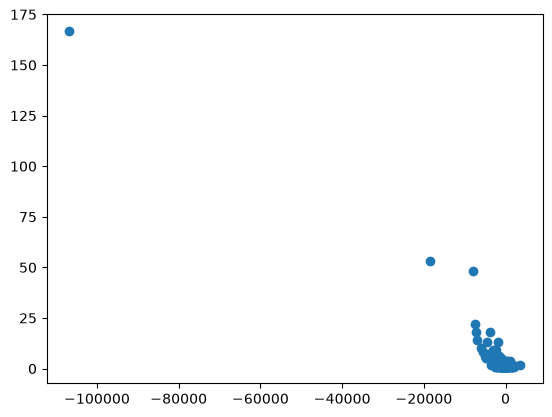

In [85]:
#Scatter plot
import matplotlib.pyplot as plt
plt.scatter(closures_enrollment_merged['Diff'], closures_enrollment_merged['Closures'])

Regression Equation: y = -0.001601096386957666x + 1.2195536476734965
R² Score: 0.92
Mean Squared Error: 9.29


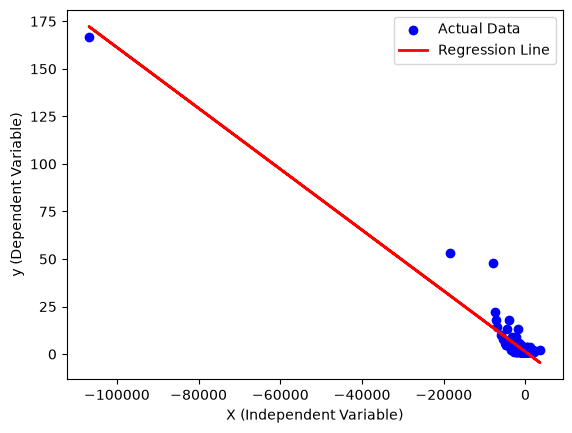

In [89]:
#linear regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Generate sample data (X must be a 2D array/matrix)
X = closures_enrollment_merged['Diff'].values.reshape(-1, 1)
y = closures_enrollment_merged['Closures'].values

# 2. Initialize the model
model = LinearRegression()

# 3. Train the model using the training data
model.fit(X, y)

# 4. Make predictions
y_pred = model.predict(X)

# 5. Extract model parameters
slope = model.coef_[0]
intercept = model.intercept_

print(f"Regression Equation: y = {slope}x + {intercept}")
print(f"R² Score: {r2_score(y, y_pred):.2f}")
print(f"Mean Squared Error: {mean_squared_error(y, y_pred):.2f}")

# 6. Plot the results
plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X, y_pred, color="red", linewidth=2, label="Regression Line")
plt.xlabel("X (Independent Variable)")
plt.ylabel("y (Dependent Variable)")
plt.legend()
plt.show()

**3. Closures by year in Detroit**

In [98]:
#filter closures to Detroit schools
closures['EntityPhysicalCity'] = closures['EntityPhysicalCity'].str.strip()
detroit = closures[closures['EntityPhysicalCity'] == 'DETROIT']

In [103]:
#split into public and charter
def public_or_charter(district):
    if str(district) in ['Detroit City School District', 'Detroit Public Schools Community District']:
        return "Public"
    else:
        return "Charter"

detroit['public_or_charter'] = detroit['DistrictOfficialName'].apply(public_or_charter)
detroit['public_or_charter'].value_counts()

public_or_charter
Public     163
Charter     81
Name: count, dtype: int64

In [108]:
#keep a few columns
detroit_small = detroit[['EntityCode', 'EntityCloseYear', 'public_or_charter']]
detroit_by_year = detroit_small.groupby(['EntityCloseYear', 'public_or_charter']).size().reset_index().rename(
    columns = {
        "EntityCloseYear": "Year",
        0: 'Closures'
        }
    ).pivot(
        index='Year',
        columns='public_or_charter',
        values='Closures'
    ).reset_index().fillna(0)
detroit_by_year.to_csv('data/detroit_closures_by_year.csv', index=False)